# Rakuten Image Classification - Colab Fine-Tuning

This standalone notebook fine-tunes an ImageNet-pretrained ResNet18 on the Rakuten product images. It keeps the complete shared validation set unchanged, reports weighted and macro F1 after every epoch, and saves the best checkpoint by validation macro F1.

The confidential images and manifests must remain in a private Google Drive folder and must not be committed to GitHub.

## 1. Configuration

The schedule first warms up the new classification head and then fine-tunes ResNet's final residual block (`layer4`). Full-network fine-tuning is evaluated separately in `03_3_image_resnet18_full_finetuning.ipynb`.

In [1]:
import json
import random
import shutil
import sys
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from PIL import Image
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.models import ResNet18_Weights, resnet18
from tqdm import tqdm

IN_COLAB                 = 'google.colab' in sys.modules
RANDOM_STATE             = 42
BATCH_SIZE               = 64
NUM_WORKERS              = 2 if IN_COLAB else 8
EXPECTED_VALIDATION_ROWS = 16_984

# Train the new head first, then adapt only the deepest ResNet block.
PHASES = [
    {'name': 'head',   'epochs': 2},
    {'name': 'layer4', 'epochs': 5},
]

HEAD_LEARNING_RATE       = 1e-3
LAYER4_LEARNING_RATE     = 1e-4
WEIGHT_DECAY             = 1e-4

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

    DRIVE_DIR            = Path('/content/drive/MyDrive/rakuten_colab')
    IMAGE_ZIP_PATH       = DRIVE_DIR / 'image_train.zip'
    MANIFEST_DRIVE_PATH  = DRIVE_DIR / 'image_split_clean.csv'
    OUTPUT_DIR           = DRIVE_DIR / 'outputs'

    LOCAL_DIR            = Path('/content/rakuten_finetuning')
    LOCAL_IMAGE_DIR      = LOCAL_DIR / 'images'
    LOCAL_MANIFEST_PATH  = LOCAL_DIR / 'image_split_clean.csv'
else:
    PROJECT_ROOT         = Path.cwd().resolve()
    while PROJECT_ROOT.name in {'03_image_fineTuning', 'notebooks'}:
        PROJECT_ROOT = PROJECT_ROOT.parent

    LOCAL_IMAGE_DIR      = PROJECT_ROOT / 'data' / 'raw' / 'images' / 'image_train'
    LOCAL_MANIFEST_PATH  = PROJECT_ROOT / 'data' / 'processed' / 'image_split_clean.csv'
    OUTPUT_DIR           = PROJECT_ROOT / 'models' / 'outputs'

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
torch.cuda.manual_seed_all(RANDOM_STATE)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type != 'cuda':
    raise RuntimeError('No GPU found. Make sure CUDA is available.')

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Mode   :', 'Colab' if IN_COLAB else 'Local')
print('Device :', torch.cuda.get_device_name(0))
print('Outputs:', OUTPUT_DIR)

Mode   : Local
Device : NVIDIA RTX PRO 2000 Blackwell Generation Laptop GPU
Outputs: /home/bquehl/Development/Rakuten2/Rakuten2/liora-capstone/models/outputs


## 2. Stage images and verify the shared split

Training rows may have been cleaned for exact duplicate leakage. Validation must contain all 16984 products from the shared split so that text and image scores remain directly comparable and suitable for fusion.

In [2]:
if IN_COLAB:
    assert IMAGE_ZIP_PATH.exists(), f'Missing private image archive: {IMAGE_ZIP_PATH}'
    assert MANIFEST_DRIVE_PATH.exists(), f'Missing split manifest: {MANIFEST_DRIVE_PATH}'

    LOCAL_DIR.mkdir(parents=True, exist_ok=True)
    LOCAL_IMAGE_DIR.mkdir(parents=True, exist_ok=True)
    shutil.copy2(MANIFEST_DRIVE_PATH, LOCAL_MANIFEST_PATH)

    # Drive is used for persistent storage, but image loading is much faster from /content.
    # Extraction is skipped when this cell is rerun within the same Colab session.
    if not any(LOCAL_IMAGE_DIR.rglob('*.jpg')):
        local_zip_path = LOCAL_DIR / IMAGE_ZIP_PATH.name
        shutil.copy2(IMAGE_ZIP_PATH, local_zip_path)
        with zipfile.ZipFile(local_zip_path) as archive:
            archive.extractall(LOCAL_IMAGE_DIR)
        local_zip_path.unlink()
else:
    assert LOCAL_IMAGE_DIR.exists(), f'Missing image directory: {LOCAL_IMAGE_DIR}'
    assert LOCAL_MANIFEST_PATH.exists(), f'Missing split manifest: {LOCAL_MANIFEST_PATH}'

# Build the filename index once; repeated recursive searches would slow down __getitem__.
image_paths      = list(LOCAL_IMAGE_DIR.rglob('*.jpg'))
filename_to_path = {path.name: path for path in image_paths}

if len(filename_to_path) != len(image_paths):
    raise ValueError('Duplicate image filenames were found inside the image directory.')

manifest            = pd.read_csv(LOCAL_MANIFEST_PATH)
required_columns    = {'row_id', 'imageid', 'productid', 'prdtypecode', 'split'}
assert required_columns.issubset(manifest.columns)
assert manifest['row_id'].is_unique
assert set(manifest['split']) == {'train', 'validation'}

# The image branch must use exactly the same validation products as the text branch.
# Training may be cleaned, but no validation row may be removed.
validation_rows     = int(manifest['split'].eq('validation').sum())
assert validation_rows == EXPECTED_VALIDATION_ROWS, (
    f'Validation contains {validation_rows:,} rows instead of {EXPECTED_VALIDATION_ROWS:,}.'
)

# CrossEntropyLoss requires contiguous targets from 0 to 26 instead of Rakuten codes.
class_codes         = sorted(manifest['prdtypecode'].astype(int).unique().tolist())
assert len(class_codes) == 27
class_to_index      = {code: index for index, code in enumerate(class_codes)}
index_to_class      = {index: code for code, index in class_to_index.items()}
manifest['target']  = manifest['prdtypecode'].astype(int).map(class_to_index)

expected_names = [
    f'image_{int(row.imageid)}_product_{int(row.productid)}.jpg'
    for row in manifest.itertuples(index=False)
]

manifest['image_path']  = [filename_to_path.get(name) for name in expected_names]
missing_mask            = manifest['image_path'].isna()

if missing_mask.any():
    examples = [expected_names[i] for i in np.flatnonzero(missing_mask.to_numpy())[:5]]
    raise FileNotFoundError(f'{missing_mask.sum():,} images are missing. Examples: {examples}')

train_manifest          = manifest.loc[manifest['split'].eq('train')].reset_index(drop=True)
validation_manifest     = manifest.loc[manifest['split'].eq('validation')].reset_index(drop=True)

display(pd.DataFrame({
    'rows': [len(train_manifest), len(validation_manifest)],
    'classes': [train_manifest['target'].nunique(), validation_manifest['target'].nunique()],
}, index=['train', 'validation']))

,rows,classes
train,62312,27
validation,16984,27


## 3. Image datasets and transformations

Training receives light stochastic augmentation. Validation uses the deterministic preprocessing supplied with the pretrained ImageNet weights.

In [3]:
weights = ResNet18_Weights.DEFAULT

# Random augmentation is applied only to training images.
# Validation preprocessing remains deterministic and matches the pretrained weights.
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.80, 1.00)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.10, contrast=0.10, saturation=0.10),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
validation_transform = weights.transforms()


class RakutenImageDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame     = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(row['image_path']) as image:
            image_tensor = self.transform(image.convert('RGB'))
        return image_tensor, int(row['target']), int(row['row_id'])


train_dataset       = RakutenImageDataset(train_manifest, train_transform)
validation_dataset  = RakutenImageDataset(validation_manifest, validation_transform)

# The seeded generator makes the shuffled training order reproducible.
loader_generator    = torch.Generator().manual_seed(RANDOM_STATE)
loader_options = {
    'batch_size'        : BATCH_SIZE,
    'num_workers'       : NUM_WORKERS,
    'pin_memory'        : True,
    'persistent_workers': NUM_WORKERS > 0,
}
train_loader = DataLoader(
    train_dataset, shuffle=True, generator=loader_generator, **loader_options
)
validation_loader = DataLoader(
    validation_dataset, shuffle=False, **loader_options
)

print(f'Training batches  : {len(train_loader):,}')
print(f'Validation batches: {len(validation_loader):,}')

Training batches  : 974
Validation batches: 266


## 4. Model, phased unfreezing and metrics

The head is warmed up first. Next, `layer4` and the head are trained with separate learning rates. Frozen BatchNorm layers remain in evaluation mode.

In [4]:
model       = resnet18(weights=weights)
model.fc    = nn.Linear(model.fc.in_features, len(class_codes))
model       = model.to(device)
criterion   = nn.CrossEntropyLoss()
amp_enabled = device.type == 'cuda'
scaler      = torch.amp.GradScaler('cuda', enabled=amp_enabled)


def configure_phase(model, phase_name):
    # Start every phase from a fully frozen model and explicitly unfreeze its scope.
    for parameter in model.parameters():
        parameter.requires_grad = False

    if phase_name == 'head':
        for parameter in model.fc.parameters():
            parameter.requires_grad = True

        optimizer = torch.optim.AdamW(
            model.fc.parameters(), lr=HEAD_LEARNING_RATE, weight_decay=WEIGHT_DECAY
        )

    elif phase_name == 'layer4':
        for parameter in model.layer4.parameters():
            parameter.requires_grad = True

        for parameter in model.fc.parameters():
            parameter.requires_grad = True

        optimizer = torch.optim.AdamW([
            {'params': model.layer4.parameters(), 'lr': LAYER4_LEARNING_RATE},
            {'params': model.fc.parameters(),     'lr': HEAD_LEARNING_RATE},
        ], weight_decay=WEIGHT_DECAY)

    else:
        raise ValueError(f'Unknown phase: {phase_name}')

    return optimizer


def set_training_mode(model, phase_name):
    # Frozen BatchNorm statistics must not change during head or layer4 fine-tuning.
    model.eval()
    model.fc.train()
    if phase_name == 'layer4':
        model.layer4.train()


def train_one_epoch(model, loader, optimizer, phase_name):
    set_training_mode(model, phase_name)
    loss_total = 0.0
    row_count  = 0

    progress = tqdm(loader, desc=f'Train {phase_name}')
    for images, targets, _ in progress:
        images  = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        # Mixed precision reduces GPU memory use and speeds up supported Colab GPUs.
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp_enabled):
            logits  = model(images)
            loss    = criterion(logits, targets)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_size  = targets.size(0)
        loss_total += loss.item() * batch_size
        row_count  += batch_size
        progress.set_postfix(loss=f'{loss_total / row_count:.4f}')

    return loss_total / row_count


@torch.no_grad()
def evaluate(model, loader, return_probabilities=False):
    model.eval()
    loss_total        = 0.0
    row_count         = 0
    all_targets       = []
    all_predictions   = []
    all_row_ids       = []
    all_probabilities = []

    for images, targets, row_ids in tqdm(loader, desc='Validation'):
        images  = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp_enabled):
            logits  = model(images)
            loss    = criterion(logits, targets)

        probabilities   = torch.softmax(logits.float(), dim=1)
        predictions     = probabilities.argmax(dim=1)
        batch_size      = targets.size(0)
        loss_total     += loss.item() * batch_size
        row_count      += batch_size
        all_targets.extend(targets.cpu().tolist())
        all_predictions.extend(predictions.cpu().tolist())
        all_row_ids.extend(row_ids.tolist())

        if return_probabilities:
            all_probabilities.append(probabilities.cpu().numpy())

    targets_array     = np.asarray(all_targets)
    predictions_array = np.asarray(all_predictions)
    result = {
        'validation_loss'   : loss_total / row_count,
        'accuracy'          : accuracy_score(targets_array, predictions_array),
        'weighted_f1'       : f1_score(targets_array, predictions_array, average='weighted', zero_division=0),
        'macro_f1'          : f1_score(targets_array, predictions_array, average='macro', zero_division=0),
        'targets'           : targets_array,
        'predictions'       : predictions_array,
        'row_ids'           : np.asarray(all_row_ids),
    }
    if return_probabilities:
        result['probabilities'] = np.concatenate(all_probabilities, axis=0)
    return result

## 5. Fine-tune and retain the best validation checkpoint

Validation is evaluated after every epoch. The checkpoint selection criterion is macro F1 because it gives every class equal importance. Training loss may be higher than validation loss because only training uses stochastic augmentation.

In [5]:
# Files in /content are temporary, so persistent results are written directly to Drive.
checkpoint_path   = OUTPUT_DIR / '03_2_resnet18_finetuned_best.pt'
history_path      = OUTPUT_DIR / '03_2_resnet18_finetuned_history.csv'
history           = []
best_macro_f1     = -np.inf
global_epoch      = 0

for phase in PHASES:
    phase_name    = phase['name']
    phase_epochs  = int(phase['epochs'])
    if phase_epochs <= 0:
        continue

    optimizer            = configure_phase(model, phase_name)
    trainable_parameters = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
    print(f'\nPhase: {phase_name} | trainable parameters: {trainable_parameters:,}')

    for phase_epoch in range(1, phase_epochs + 1):
        global_epoch     += 1
        train_loss        = train_one_epoch(model, train_loader, optimizer, phase_name)
        validation_result = evaluate(model, validation_loader)

        epoch_result = {
            'global_epoch'      : global_epoch,
            'phase'             : phase_name,
            'phase_epoch'       : phase_epoch,
            'train_loss'        : train_loss,
            'validation_loss'   : validation_result['validation_loss'],
            'accuracy'          : validation_result['accuracy'],
            'weighted_f1'       : validation_result['weighted_f1'],
            'macro_f1'          : validation_result['macro_f1'],
        }
        history.append(epoch_result)
        pd.DataFrame(history).to_csv(history_path, index=False)
        display(pd.DataFrame([epoch_result]).style.format({
            'train_loss'        : '{:.4f}',
            'validation_loss'   : '{:.4f}',
            'accuracy'          : '{:.4f}',
            'weighted_f1'       : '{:.4f}',
            'macro_f1'          : '{:.4f}',
        }))

        # Macro F1 gives all 27 classes equal weight and controls checkpoint selection.
        if validation_result['macro_f1'] > best_macro_f1:
            best_macro_f1 = validation_result['macro_f1']
            torch.save({
                'model_name'        : 'resnet18',
                'model_state_dict'  : {
                    name: tensor.detach().cpu()
                    for name, tensor in model.state_dict().items()
                },
                'class_to_index'    : class_to_index,
                'phase'             : phase_name,
                'global_epoch'      : global_epoch,
                'validation_metrics': {
                    key: float(validation_result[key])
                    for key in ['validation_loss', 'accuracy', 'weighted_f1', 'macro_f1']
                },
            }, checkpoint_path)
            print(f'New best checkpoint: macro F1 = {best_macro_f1:.4f}')

    # Begin the next phase from the best model seen so far, not merely the last epoch.
    best_checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
    model.load_state_dict(best_checkpoint['model_state_dict'])

print(f'Best checkpoint saved to: {checkpoint_path}')
print(f'Best validation macro F1: {best_macro_f1:.4f}')


Phase: head | trainable parameters: 13,851


Validation: 100%|██████████| 266/266 [00:09<00:00, 27.65it/s]


,global_epoch,phase,phase_epoch,train_loss,validation_loss,accuracy,weighted_f1,macro_f1
0,1,head,1,1.8624,1.6680,0.5042,0.4863,0.4317


New best checkpoint: macro F1 = 0.4317


Validation: 100%|██████████| 266/266 [00:12<00:00, 20.54it/s]


,global_epoch,phase,phase_epoch,train_loss,validation_loss,accuracy,weighted_f1,macro_f1
0,2,head,2,1.6548,1.6399,0.5115,0.4956,0.4472


... (12 outputs left out)

New best checkpoint: macro F1 = 0.5902


Validation: 100%|██████████| 266/266 [00:15<00:00, 17.58it/s]


,global_epoch,phase,phase_epoch,train_loss,validation_loss,accuracy,weighted_f1,macro_f1
0,7,layer4,5,0.6927,1.4990,0.6113,0.6064,0.5714


Best checkpoint saved to: /home/bquehl/Development/Rakuten2/Rakuten2/liora-capstone/models/outputs/resnet18_finetuned_best.pt
Best validation macro F1: 0.5902


## 6. Training curves

Use validation loss and macro F1 to assess generalisation. A falling training loss combined with a rising validation loss indicates overfitting.

,global_epoch,phase,phase_epoch,train_loss,validation_loss,accuracy,weighted_f1,macro_f1
0,1,head,1,1.8624,1.6680,0.5042,0.4863,0.4317
1,2,head,2,1.6548,1.6399,0.5115,0.4956,0.4472
2,3,layer4,1,1.5023,1.3989,0.5856,0.5766,0.5232
3,4,layer4,2,1.2000,1.3124,0.6135,0.6084,0.5723
4,5,layer4,3,1.0137,1.3412,0.6151,0.6115,0.5792
5,6,layer4,4,0.8506,1.3729,0.6250,0.6238,0.5902
6,7,layer4,5,0.6927,1.4990,0.6113,0.6064,0.5714


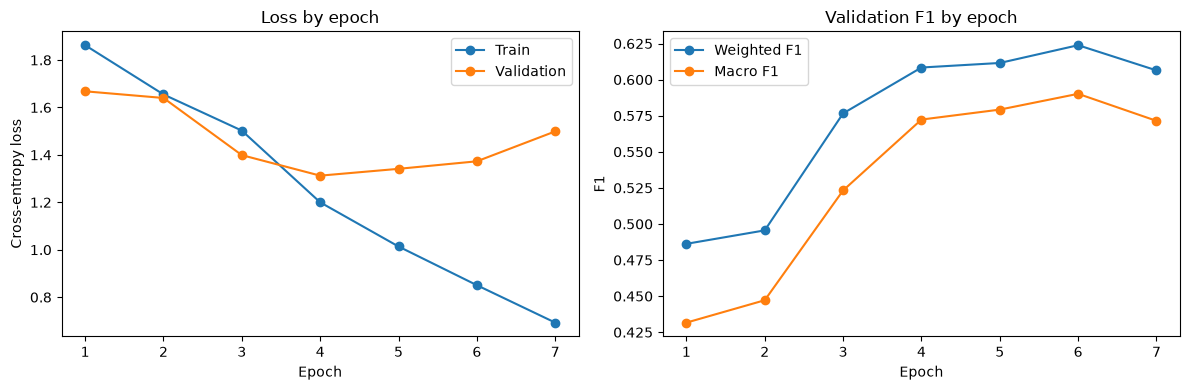

In [6]:
history_frame = pd.DataFrame(history)
display(history_frame.style.format({
    'train_loss'        : '{:.4f}',
    'validation_loss'   : '{:.4f}',
    'accuracy'          : '{:.4f}',
    'weighted_f1'       : '{:.4f}',
    'macro_f1'          : '{:.4f}',
}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_frame['global_epoch'], history_frame['train_loss'], marker='o', label='Train')
axes[0].plot(history_frame['global_epoch'], history_frame['validation_loss'], marker='o', label='Validation')
axes[0].set(title='Loss by epoch', xlabel='Epoch', ylabel='Cross-entropy loss')
axes[0].legend()

axes[1].plot(history_frame['global_epoch'], history_frame['weighted_f1'], marker='o', label='Weighted F1')
axes[1].plot(history_frame['global_epoch'], history_frame['macro_f1'], marker='o', label='Macro F1')
axes[1].set(title='Validation F1 by epoch', xlabel='Epoch', ylabel='F1')
axes[1].legend()
plt.tight_layout()
plt.show()

## 7. Final evaluation and fusion-ready outputs

The best checkpoint is evaluated on the complete shared validation set. Predictions retain `row_id` and all 27 class probabilities so they can later be joined with text-model outputs.

In [7]:
best_checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
model.load_state_dict(best_checkpoint['model_state_dict'])
final_result    = evaluate(model, validation_loader, return_probabilities=True)

final_metrics = pd.DataFrame([{
    key: final_result[key]
    for key in ['validation_loss', 'accuracy', 'weighted_f1', 'macro_f1']
}], index=['resnet18_finetuned'])
display(final_metrics.style.format('{:.4f}'))

precision, recall, per_class_f1, support = precision_recall_fscore_support(
    final_result['targets'],
    final_result['predictions'],
    labels=np.arange(len(class_codes)),
    zero_division=0,
)
per_class_metrics = pd.DataFrame({
    'prdtypecode'   : class_codes,
    'precision'     : precision,
    'recall'        : recall,
    'f1'            : per_class_f1,
    'support'       : support,
}).sort_values('f1')
display(per_class_metrics.style.format({
    'precision'     : '{:.3f}',
    'recall'        : '{:.3f}',
    'f1'            : '{:.3f}',
}))

# Keep row_id and every class probability so text and image outputs can be joined later.
prediction_frame = pd.DataFrame({
    'row_id'                : final_result['row_ids'],
    'true_prdtypecode'      : [index_to_class[int(value)] for value in final_result['targets']],
    'predicted_prdtypecode' : [index_to_class[int(value)] for value in final_result['predictions']],
})
for class_index, class_code in enumerate(class_codes):
    prediction_frame[f'prob_{class_code}'] = final_result['probabilities'][:, class_index]

predictions_path = OUTPUT_DIR / '03_2_resnet18_finetuned_validation_predictions.csv'
per_class_path   = OUTPUT_DIR / '03_2_resnet18_finetuned_validation_per_class.csv'
metrics_path     = OUTPUT_DIR / '03_2_resnet18_finetuned_validation_metrics.json'

prediction_frame.to_csv(predictions_path, index=False)
per_class_metrics.to_csv(per_class_path, index=False)
metrics_path.write_text(json.dumps({
    key: float(final_result[key])
    for key in ['validation_loss', 'accuracy', 'weighted_f1', 'macro_f1']
}, indent=2))

assert len(prediction_frame) == EXPECTED_VALIDATION_ROWS
assert prediction_frame['row_id'].is_unique
print('Saved:', predictions_path)
print('Saved:', per_class_path)
print('Saved:', metrics_path)

Validation: 100%|██████████| 266/266 [00:15<00:00, 17.68it/s]


,validation_loss,accuracy,weighted_f1,macro_f1
resnet18_finetuned,1.3729,0.6250,0.6238,0.5902


,prdtypecode,precision,recall,f1,support
8,1281,0.401,0.244,0.303,414
24,2585,0.432,0.347,0.385,499
7,1280,0.368,0.448,0.404,974
6,1180,0.545,0.359,0.433,153
11,1302,0.489,0.410,0.446,498
2,50,0.388,0.530,0.448,336
22,2582,0.489,0.419,0.451,518
17,2220,0.500,0.448,0.473,165
12,1320,0.506,0.492,0.499,648
16,2060,0.514,0.492,0.503,999


Saved: /home/bquehl/Development/Rakuten2/Rakuten2/liora-capstone/models/outputs/image_validation_predictions_finetuned.csv
Saved: /home/bquehl/Development/Rakuten2/Rakuten2/liora-capstone/models/outputs/image_validation_metrics_per_class_finetuned.csv
Saved: /home/bquehl/Development/Rakuten2/Rakuten2/liora-capstone/models/outputs/image_validation_metrics_finetuned.json


## Interpretation checklist

Compare the fine-tuned `layer4` model with the frozen ResNet18 on exactly the same 16984 validation products. Report validation loss, accuracy, weighted F1, macro F1 and F1 per class. Full-network fine-tuning starting from this `resnet18_finetuned_best.pt` checkpoint is evaluated separately in `03_3_image_resnet18_full_finetuning.ipynb`.